# Berlin Urban Flood — Phase 2: Real-data GeoTIFF Diagnostic (FIXED v2)

**Fix:** Some Zenodo ZIP members use ZIP compression methods not supported by Kaggle's `zipfile`. This notebook prints each method and extracts individual compressed members through HTTP Range requests using Deflate64 / Zstandard if required. It does **not** download the full archives.

**Goal:** Inspect three Berlin GeoTIFFs and optionally run a two-feature mini Random Forest diagnostic. This is **not** the original RF/U-Net baseline.

Run top to bottom, starting with Internet **On**. CPU is sufficient. If the server ignores Range requests, the notebook aborts safely.


## 1. Inspect environment and disk

In [1]:
import sys, os, shutil, json, time, subprocess, importlib.util
from pathlib import Path
import numpy as np

BASE=Path('/kaggle') if Path('/kaggle').exists() else Path('/tmp')
TEMP=BASE/'tmp'/'berlin_phase2_real'
TEMP.mkdir(parents=True, exist_ok=True)
OUT=Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/tmp')

def space(p):
    u=shutil.disk_usage(p)
    return {'total_GiB':round(u.total/2**30,2),'free_GiB':round(u.free/2**30,2)}
print('Python',sys.version.split()[0]); print('TEMP',TEMP,space(TEMP)); print('OUTPUT',OUT,space(OUT))
print('NOTE: downloaded TIFFs in TEMP vanish after this Kaggle session.')

Python 3.13.15
TEMP /kaggle/tmp/berlin_phase2_real {'total_GiB': 8156.88, 'free_GiB': 1048.79}
OUTPUT /kaggle/working {'total_GiB': 19.52, 'free_GiB': 19.5}
NOTE: downloaded TIFFs in TEMP vanish after this Kaggle session.


## 2. Install lightweight dependencies (only if missing)

In [2]:
module_map={'remotezip':'remotezip','rasterio':'rasterio','scikit-learn':'sklearn',
            'matplotlib':'matplotlib','pandas':'pandas','requests':'requests',
            'inflate64':'inflate64','zstandard':'zstandard'}
need=[p for p,m in module_map.items() if importlib.util.find_spec(m) is None]
if need:
    print('Installing:',need)
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*need])
else:
    print('Packages already present.')
import requests, rasterio, pandas as pd
from remotezip import RemoteZip
print('rasterio',rasterio.__version__)


Installing: ['remotezip', 'inflate64']
rasterio 1.5.1


## 3. Confirm file names from Zenodo without downloading whole archives

In [3]:
RECORD='7221058'
API=f'https://zenodo.org/api/records/{RECORD}'
r=requests.get(API,timeout=50); r.raise_for_status()
files=r.json().get('files',[])
print(pd.DataFrame([{'name':f['key'],'size_GB':round(f['size']/1e9,3),'checksum':f.get('checksum','')} for f in files]).to_string(index=False))

def zip_url(name):
    return f'https://zenodo.org/records/{RECORD}/files/{name}?download=1'

SELECTED = {
   'Predictive_features.zip': ['CN.tif','DEM_depth_1m_clip.tif'],
   'Water_depth_TELEMAC_2D.zip':['SA1/WD_60mm.tif'],
}
ZIP_METHOD={0:'Stored',8:'Deflate',9:'Deflate64',12:'BZIP2',14:'ZIP LZMA',20:'Zstandard (old ID)',93:'Zstandard'}
for arch, members in SELECTED.items():
    print('\nInspecting',arch)
    with RemoteZip(zip_url(arch),timeout=180) as z:
        infos={i.filename:i for i in z.infolist()}
        for member in members:
            if member not in infos:
                raise FileNotFoundError(f'{member} not in {arch}. Available: {list(infos)[:30]}')
            i=infos[member]
            print('  ',member,'method=',i.compress_type,
                  ZIP_METHOD.get(i.compress_type,'unsupported/unknown'),
                  'compressed=',round(i.compress_size/1e6,1),'MB',
                  'extracted=',round(i.file_size/1e6,1),'MB')


                      name  size_GB                             checksum
Water_depth_TELEMAC_2D.zip    2.907 md5:3ae2d4a372afd48e044cee8a393193f9
   Predictive_features.zip   20.764 md5:cb2c25df042cc2df13cb23fb0732b763

Inspecting Predictive_features.zip
   CN.tif method= 9 Deflate64 compressed= 12.4 MB extracted= 31.6 MB
   DEM_depth_1m_clip.tif method= 9 Deflate64 compressed= 488.3 MB extracted= 515.6 MB

Inspecting Water_depth_TELEMAC_2D.zip
   SA1/WD_60mm.tif method= 8 Deflate compressed= 77.2 MB extracted= 93.2 MB


## 4. Extract three selected TIFFs (fixed)

The notebook prints the ZIP compression method (e.g. `9 = Deflate64`, `93 = Zstandard`). 
It streams only each selected member's compressed bytes and validates extracted size and CRC. 
Expected compressed download is roughly 578 MB, not 23.7 GB. 
Some transfers may fail due to Zenodo/Kaggle network limits; retry if a short-lived network error occurs.


In [4]:
# Custom HTTP Range extraction: works without downloading either complete Zenodo ZIP.
# Standard ZIP methods still use RemoteZip.open(); special methods 9 and 20/93
# use their corresponding streaming decompressors on raw compressed member bytes.
import struct, zlib, bz2
from contextlib import closing

RANGE_CHUNK = 8 * 2**20  # 8 MiB of compressed bytes per HTTP request

def fetch_range(url, start, length, session):
    if length == 0:
        return b''
    end = start + length - 1
    with session.get(url, headers={'Range':f'bytes={start}-{end}', 'Accept-Encoding':'identity'},
                     timeout=(30,180), stream=True) as response:
        if response.status_code != 206:
            raise RuntimeError('Zenodo did not honor Range requests: HTTP '
                               f'{response.status_code}. Stopping to avoid full ZIP download.')
        returned_range = response.headers.get('Content-Range','')
        if not returned_range.startswith(f'bytes {start}-{end}/'):
            raise RuntimeError('Unexpected HTTP Content-Range: '+str(returned_range))
        data = bytearray()
        for chunk in response.iter_content(chunk_size=2**20):
            data.extend(chunk)
            if len(data)>length:
                raise RuntimeError('Server returned extra data; canceled to protect disk.')
    if len(data)!=length:
        raise IOError(f'HTTP Range truncated: {len(data)} != {length}')
    return bytes(data)


def zip_data_offset(archive_url, info, session):
    # ZipInfo.header_offset is local file-header offset, NOT the compressed payload.
    header=fetch_range(archive_url,info.header_offset,30,session)
    (signature, version, flags, method, mtime, mdate, crc, comp32, raw32,
     name_len, extra_len)=struct.unpack('<IHHHHHIIIHH',header)
    if signature != 0x04034B50:
        raise ValueError('Invalid local ZIP header signature; cannot safely locate member.')
    if flags & 1:
        raise RuntimeError('Encrypted ZIP member is not supported.')
    if method != info.compress_type:
        raise ValueError(f'Local ZIP method {method} differs from directory {info.compress_type}')
    return info.header_offset + 30 + name_len + extra_len


def extract_member(archive, member):
    dest=TEMP/archive.replace('.zip','')/member
    dest.parent.mkdir(parents=True,exist_ok=True)
    url=zip_url(archive)
    with RemoteZip(url,timeout=180) as z:
        info=z.getinfo(member)
        expected=info.file_size
        print(f'\n{archive} / {member}: method {info.compress_type} '
              f'({ZIP_METHOD.get(info.compress_type,"unknown")}), '
              f'{info.compress_size/1e6:.1f} MB compressed, {expected/1e6:.1f} MB extracted')
        if dest.exists() and dest.stat().st_size==expected:
            print('CACHED:',dest)
            return dest
        free=shutil.disk_usage(TEMP).free
        if free < expected + 1*2**30:
            raise RuntimeError(f'Insufficient scratch storage: free {free/2**30:.1f} GiB')
        tempdest=dest.with_suffix(dest.suffix+'.part')
        if tempdest.exists():tempdest.unlink()
        n=0; crc=0; t=time.time()
        try:
            if info.compress_type in (0,8,12,14):
                with z.open(info) as src, tempdest.open('wb') as out:
                    while True:
                        block=src.read(2**20)
                        if not block:break
                        out.write(block)
                        n+=len(block)
                        crc=zlib.crc32(block,crc)
            elif info.compress_type in (9,20,93):
                if info.compress_type==9:
                    import inflate64
                    decoder=inflate64.Inflater()
                    decode=decoder.inflate
                    finish=lambda: b''
                else:
                    import zstandard as zstd
                    decoder=zstd.ZstdDecompressor().decompressobj()
                    decode=decoder.decompress
                    finish=decoder.flush
                with requests.Session() as session:
                    offset=zip_data_offset(url,info,session)
                    with tempdest.open('wb') as out:
                        for pos in range(0,info.compress_size,RANGE_CHUNK):
                            length=min(RANGE_CHUNK,info.compress_size-pos)
                            compressed=fetch_range(url,offset+pos,length,session)
                            block=decode(compressed)
                            if block:
                                out.write(block);n+=len(block);crc=zlib.crc32(block,crc)
                            # Print a small progress signal every ~64 MB compressed.
                            if (pos//RANGE_CHUNK)%8==0:
                                print(f'    downloaded {min(pos+length,info.compress_size)/1e6:.1f}'
                                      f'/{info.compress_size/1e6:.1f} MB compressed')
                        tail=finish()
                        if tail:
                            out.write(tail);n+=len(tail);crc=zlib.crc32(tail,crc)
            else:
                raise NotImplementedError('Unsupported ZIP compression method: '
                                          f'{info.compress_type}. Send this number to ChatGPT.')
            if n!=expected:
                raise IOError(f'Decompressed file size mismatch {n} != {expected}')
            if (crc & 0xffffffff)!=info.CRC:
                raise IOError(f'CRC mismatch for {member}: file may be corrupted')
            tempdest.replace(dest)
            print('EXTRACTED:',member,f'{n/1e6:.1f} MB',
                  'in',f'{time.time()-t:.1f}s','CRC OK')
        finally:
            if tempdest.exists():tempdest.unlink()
    return dest

paths={}
for archive,members in SELECTED.items():
    for member in members:
        paths[member]=extract_member(archive,member)
print('Done. Free disk:',space(TEMP))



Predictive_features.zip / CN.tif: method 9 (Deflate64), 12.4 MB compressed, 31.6 MB extracted
    downloaded 8.4/12.4 MB compressed
EXTRACTED: CN.tif 31.6 MB in 15.2s CRC OK

Predictive_features.zip / DEM_depth_1m_clip.tif: method 9 (Deflate64), 488.3 MB compressed, 515.6 MB extracted
    downloaded 8.4/488.3 MB compressed
    downloaded 75.5/488.3 MB compressed
    downloaded 142.6/488.3 MB compressed
    downloaded 209.7/488.3 MB compressed
    downloaded 276.8/488.3 MB compressed
    downloaded 343.9/488.3 MB compressed
    downloaded 411.0/488.3 MB compressed
    downloaded 478.2/488.3 MB compressed
EXTRACTED: DEM_depth_1m_clip.tif 515.6 MB in 189.7s CRC OK

Water_depth_TELEMAC_2D.zip / SA1/WD_60mm.tif: method 8 (Deflate), 77.2 MB compressed, 93.2 MB extracted
EXTRACTED: SA1/WD_60mm.tif 93.2 MB in 84.4s CRC OK
Done. Free disk: {'total_GiB': 8156.88, 'free_GiB': 1048.17}


## 5. Inspect raster metadata, nodata, and spatial overlap

In [6]:
from rasterio.warp import transform_bounds
from rasterio.coords import disjoint_bounds

if not isinstance(globals().get('paths'),dict) or len(paths) != 3:
    raise RuntimeError('Cell 4 has not extracted all three TIFFs yet. Run cell 4 before this cell.')

def raster_info(path):
    with rasterio.open(path) as ds:
        return dict(file=Path(path).name,width=ds.width,height=ds.height,
                    count=ds.count,dtype=ds.dtypes[0],crs=str(ds.crs),
                    bounds=tuple(round(float(k),2) for k in ds.bounds),
                    pixel_size=tuple(round(abs(float(k)),3) for k in ds.res),
                    nodata=str(ds.nodata),size_GiB=round(Path(path).stat().st_size/2**30,3))
info=pd.DataFrame([raster_info(v) for v in paths.values()])
print(info.to_string(index=False))
info.to_csv(OUT/'berlin_phase2_geotiff_metadata.csv',index=False)

TARGET=paths['SA1/WD_60mm.tif']
with rasterio.open(TARGET) as yds:
    assert yds.crs is not None, 'Depth TIFF has no CRS; cannot reliably align.'
    print('\nTarget grid CRS:',yds.crs,'bounds:',yds.bounds)
    for feature in ['CN.tif','DEM_depth_1m_clip.tif']:
        with rasterio.open(paths[feature]) as ds:
            if ds.crs is None:
                print(feature,'CRS missing: alignment not safe'); continue
            src_in_target=transform_bounds(ds.crs,yds.crs,*ds.bounds,densify_pts=21)
            overlap=not disjoint_bounds(src_in_target,yds.bounds)
            print(feature, 'overlaps SA1?',overlap,'source bounds in target CRS:',tuple(round(x,1) for x in src_in_target))


                 file  width  height  count   dtype        crs                                         bounds pixel_size nodata  size_GiB
               CN.tif  45787   37739      1    int8 EPSG:25833 (370000.65, 5799520.59, 415786.68, 5837259.39) (1.0, 1.0)   None     0.029
DEM_depth_1m_clip.tif  45787   37739      1 float32 EPSG:25833 (370000.65, 5799520.59, 415786.68, 5837259.39) (1.0, 1.0)    nan     0.480
          WD_60mm.tif   3253    3577      1 float64 EPSG:25833 (384570.61, 5823429.98, 387823.71, 5827007.48) (1.0, 1.0)    nan     0.087

Target grid CRS: EPSG:25833 bounds: BoundingBox(left=384570.6118, bottom=5823429.9831, right=387823.7089, top=5827007.4799)
CN.tif overlaps SA1? True source bounds in target CRS: (370000.7, 5799520.6, 415786.7, 5837259.4)
DEM_depth_1m_clip.tif overlaps SA1? True source bounds in target CRS: (370000.7, 5799520.6, 415786.7, 5837259.4)


## 6. Inspect real rasters visually (downsampled preview)

Do not confuse these preview images with predictions. This is a sanity check on actual GIS data.

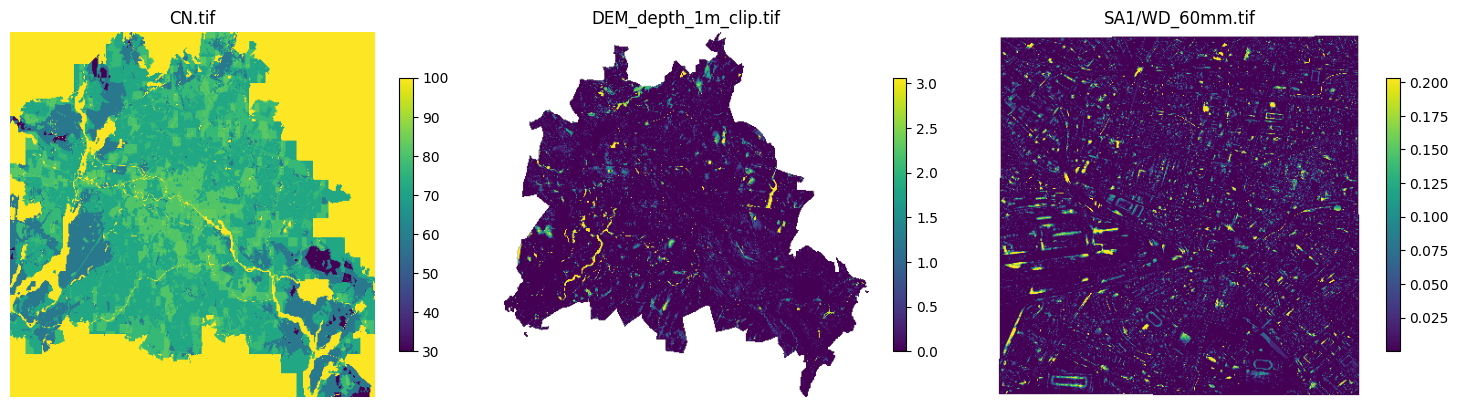

In [7]:
import matplotlib.pyplot as plt
from rasterio.enums import Resampling
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,(name,path) in zip(axes,paths.items()):
    with rasterio.open(path) as ds:
        a=ds.read(1,out_shape=(400,400),resampling=Resampling.nearest,masked=True).astype('float32')
        a=np.asarray(a.filled(np.nan),dtype='float32')
        a[~np.isfinite(a)]=np.nan
        lo,hi=np.nanpercentile(a[np.isfinite(a)],[1,99]) if np.isfinite(a).any() else (0,1)
        im=ax.imshow(a,cmap='viridis',vmin=lo,vmax=hi)
        ax.set_title(name);ax.axis('off');fig.colorbar(im,ax=ax,shrink=.75)
fig.tight_layout()
fig.savefig(OUT/'berlin_phase2_real_raster_preview.png',dpi=140)
plt.show()

## 7. OPTIONAL — Run a **two-feature Random Forest diagnostic** using real raster pixels

This is **NOT** the published RF baseline. It uses only `CN` and `DEM_depth_1m_clip` and rainfall fixed to 60 mm (rainfall cannot be learned from one scenario). Pixels are grouped by **non-overlapping geographic tiles** in the train/validation split to reduce spatial leakage. If rasters do not overlap or contain too few valid pixels, the diagnostic will **skip with an explanation** rather than invent values.

For scientific reproduction we will later need all 12 spatial predictors, multiple rainfall scenarios, matching preprocessing, and the original train/test area split.

{
  "status": "PARTIAL_FEATURE_REAL_DATA_DIAGNOSTIC_NOT_PAPER_BASELINE",
  "source_record": "7221058",
  "study_area": "SA1",
  "rainfall_mm": 60,
  "predictors": [
    "CN.tif",
    "DEM_depth_1m_clip.tif"
  ],
  "n_train_pixels": 16200,
  "n_val_pixels": 5400,
  "n_train_tiles": 27,
  "n_val_tiles": 9,
  "rmse": 0.07649204677727048,
  "mae": 0.02764351784442751,
  "r2": 0.08707415865087131,
  "depth_train_min": 9.997399956773734e-07,
  "depth_train_max": 0.5670412182807922,
  "depth_val_min": 9.997312417908688e-07,
  "depth_val_max": 2.073052406311035
}


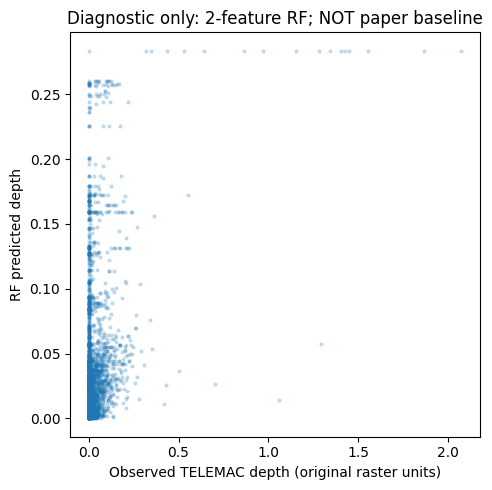

In [8]:
from rasterio.windows import Window, transform as window_transform
from rasterio.warp import reproject
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

rng=np.random.default_rng(42)
feature_names=['CN.tif','DEM_depth_1m_clip.tif']
rows=[]
N_TILES_AXIS=6
PER_TILE=600
with rasterio.open(TARGET) as depth, rasterio.open(paths[feature_names[0]]) as cn, rasterio.open(paths[feature_names[1]]) as dem:
    if any(ds.crs is None for ds in (depth,cn,dem)):
        print('SKIP: Missing CRS; cannot align rasters reliably.')
    else:
        tile_id=0
        for iy in range(N_TILES_AXIS):
            for ix in range(N_TILES_AXIS):
                # Sample distinct, non-overlapping 256x256 windows spread across SA1.
                row0=min(int((iy+.5)*depth.height/N_TILES_AXIS),max(0,depth.height-256))
                col0=min(int((ix+.5)*depth.width/N_TILES_AXIS),max(0,depth.width-256))
                h=min(256,depth.height-row0); w=min(256,depth.width-col0)
                if h<=0 or w<=0: continue
                win=Window(col0,row0,w,h)
                y=depth.read(1,window=win,masked=True).astype('float32').filled(np.nan)
                geo=window_transform(win,depth.transform)
                feat=[]
                for ds,method in [(cn,Resampling.nearest),(dem,Resampling.bilinear)]:
                    dest=np.full((h,w),np.nan,dtype='float32')
                    reproject(source=rasterio.band(ds,1),destination=dest,
                              src_transform=ds.transform,src_crs=ds.crs,src_nodata=ds.nodata,
                              dst_transform=geo,dst_crs=depth.crs,dst_nodata=np.nan,
                              resampling=method,init_dest_nodata=True)
                    feat.append(dest)
                valid=np.isfinite(y) & (y>=0)
                for f in feat:valid &= np.isfinite(f)
                yy,xx=np.where(valid)
                if len(yy)<30:
                    tile_id+=1;continue
                picked=rng.choice(len(yy),size=min(PER_TILE,len(yy)),replace=False)
                u,v=yy[picked],xx[picked]
                fmat=np.column_stack((feat[0][u,v],feat[1][u,v])).astype('float32')
                rows.append((fmat,y[u,v],np.full(len(u),tile_id)))
                tile_id+=1

if len(rows)<4:
    print(f'SKIP RF: only {len(rows)} valid tiles. Check metadata/overlap and nodata values.')
else:
    X=np.concatenate([p[0] for p in rows]);y=np.concatenate([p[1] for p in rows]);groups=np.concatenate([p[2] for p in rows])
    # No rainfall column: 60mm is constant, so adding it would not help learning.
    if len(np.unique(groups))<4:
        print('SKIP RF: too few distinct geographic tiles.')
    else:
        train_ix,test_ix=next(GroupShuffleSplit(test_size=.25,n_splits=1,random_state=42).split(X,y,groups))
        rf=RandomForestRegressor(n_estimators=30,min_samples_leaf=5,n_jobs=4,random_state=42)
        rf.fit(X[train_ix],y[train_ix]);pred=rf.predict(X[test_ix])
        metrics={
          'status':'PARTIAL_FEATURE_REAL_DATA_DIAGNOSTIC_NOT_PAPER_BASELINE',
          'source_record':RECORD,'study_area':'SA1','rainfall_mm':60,
          'predictors':feature_names,'n_train_pixels':int(len(train_ix)),
          'n_val_pixels':int(len(test_ix)),'n_train_tiles':int(len(np.unique(groups[train_ix]))),
          'n_val_tiles':int(len(np.unique(groups[test_ix]))),
          'rmse':float(np.sqrt(mean_squared_error(y[test_ix],pred))),
          'mae':float(mean_absolute_error(y[test_ix],pred)),
          'r2':float(r2_score(y[test_ix],pred)) if np.var(y[test_ix])>0 else None,
          'depth_train_min':float(np.min(y[train_ix])), 'depth_train_max':float(np.max(y[train_ix])),
          'depth_val_min':float(np.min(y[test_ix])), 'depth_val_max':float(np.max(y[test_ix])),
        }
        print(json.dumps(metrics,indent=2))
        (OUT/'berlin_phase2_rf_diagnostic.json').write_text(json.dumps(metrics,indent=2))
        plt.figure(figsize=(5,5))
        plt.scatter(y[test_ix],pred,s=4,alpha=.2)
        plt.xlabel('Observed TELEMAC depth (original raster units)');plt.ylabel('RF predicted depth')
        plt.title('Diagnostic only: 2-feature RF; NOT paper baseline')
        plt.tight_layout();plt.savefig(OUT/'berlin_phase2_rf_scatter.png',dpi=150);plt.show()


## 8. Next research step

Send these outputs back to ChatGPT:

1. `berlin_phase2_geotiff_metadata.csv`
2. `berlin_phase2_real_raster_preview.png`
3. `berlin_phase2_rf_diagnostic.json` **if** the optional RF diagnostic ran
4. Any tracebacks, especially ZIP download/CRS/NoData errors

**Do not call the 2-feature result a reproduction.** We will use these metadata to build aligned 13-channel samples for the actual U-Net and RF baselines without guessing the spatial grids.

**Important provenance note:** The final journal article cites Zenodo record `7516408` and a code DOI `7661174`, while the public GitHub repository used in Phase 1 points to Zenodo `7221058`. Before final scientific reproduction, confirm whether the archived versions and dataset contents are identical, and record the exact version/commit.